# Лінійна регресія

## А. Генерування фіч (регресорів, x)

Згенеруйте вибірку регресорів об'єму n=100 відповідно до варіанту

1. N(0, 1)
2. U[-5, 5]
3. Gamma(3, 3)
4. Exp(0.2)

## Б. Генерація похибок $\varepsilon_i$

Згенеруйте n=100 похибок відповідно до варіантів

1. N(0, 0.2)
2. U[-0.25, 0.2]
4. Exp(0.2)

## В. Побудуйте таргети (відгуки, у) за наступною моделлю регресії

$$y_i = \theta_0 + x_i \theta_1 + \varepsilon_i$$
де $\theta=(0.5, -0.5)$, $1\leq i\leq n$

## Г. Exploratory data analysis
- зобразіть окремо гістограми $x$ та $y$
- Зобразіть діаграму розсіювання пар $x, y$
- Чи має місце лінійна залежність
- Порахуйте кореляцію спірмена (коефіцієнт лінійної кореляції)


## Д. Оцінка параметрів моделі за МНК
- оцініть параметри моделі за МНК, порахуйте значення функціоналу МНК
- Зробіть передбачення
- Зобразіть передбачення разом із таргетами
- Зобразіть гістограму залишків (передбачення - таргети)
- Яким є середнє відхилення?
- Порахуйте лінійну кореляцію між залишками та передбаченнями. Чи вони незалежні?
- Чи вдалося гарно оцінити параметри $\theta$.  Якщо не вийшло, то яка в цьому причина?

**Варіант 1:** $x \sim N(0, 1)$, $\varepsilon \sim N(0, 0.2)$ (0.2 — дисперсія, як у лекціях $N(\mu, \sigma^2)$)

In [1]:
import numpy as np
from matplotlib import pyplot as plt

# А. Генерування фіч

In [2]:
n = 100

x = np.random.normal(0, 1, size=n)

In [3]:
x[:5]

array([ 1.25325355,  0.6682613 ,  0.78390423,  0.0065037 , -0.08141612])

In [4]:
x.mean(), x.var()

(np.float64(0.06957675833430557), np.float64(1.068681654064756))

# Б. Генерація похибок

In [5]:
sigma2 = 0.2  # variance

eps = np.random.normal(0, sigma2 ** 0.5, size=n)

In [6]:
eps.mean(), eps.var()

(np.float64(0.05995141056785966), np.float64(0.1424714541158059))

# В. Таргети

$y_i = \theta_0 + x_i \theta_1 + \varepsilon_i$, $\theta=(0.5, -0.5)$

In [7]:
theta = np.array([0.5, -0.5])

y = theta[0] + x * theta[1] + eps

In [8]:
y[:5]

array([-0.06501668,  0.96030511,  0.57975099,  1.17912208,  1.0098802 ])

# Г. Exploratory data analysis

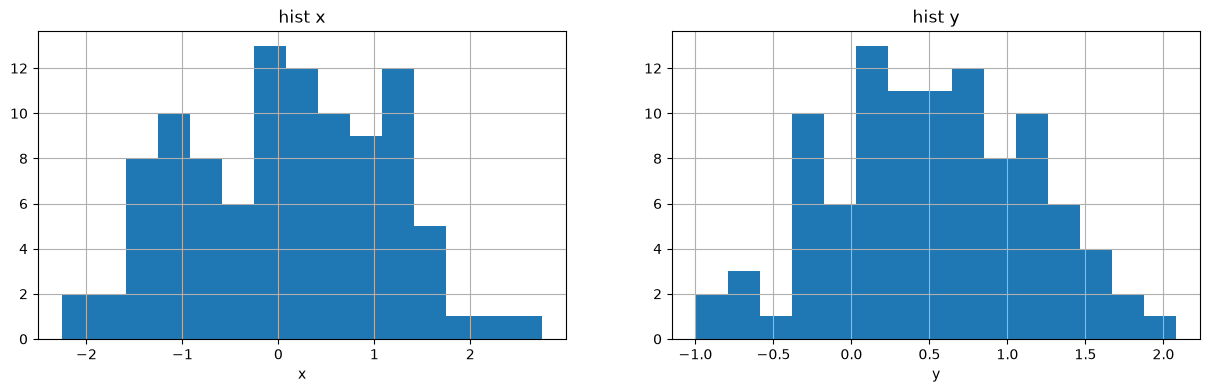

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(15, 4))

ax = axs[0]
ax.hist(x, bins=15)
ax.set_xlabel('x')
ax.set_title('hist x')
ax.grid()

ax = axs[1]
ax.hist(y, bins=15)
ax.set_xlabel('y')
ax.set_title('hist y')
ax.grid()

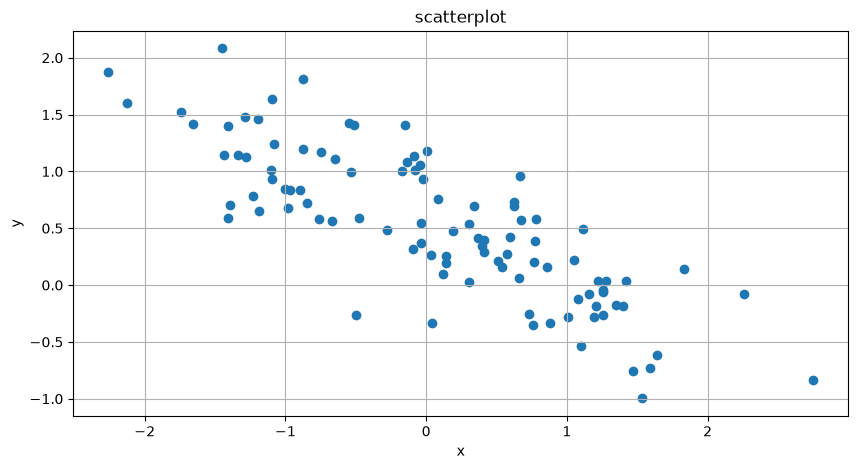

In [10]:
plt.figure(figsize=(10, 5))
plt.scatter(x, y)
plt.xlabel('x')
plt.ylabel('y')
plt.title('scatterplot')
plt.grid()

Точки лежать уздовж спадної прямої, розкид навколо неї невеликий, отже лінійна залежність є, і вона від'ємна ($\theta_1 = -0.5 < 0$).

In [11]:
# лінійна кореляція (Пірсона)
np.corrcoef(x, y)

array([[ 1.        , -0.81559575],
       [-0.81559575,  1.        ]])

In [12]:
r = np.corrcoef(x, y)[0, 1]
r

np.float64(-0.815595748420501)

In [13]:
# кореляція Спірмена = кореляція Пірсона між рангами
from scipy.stats import spearmanr, rankdata

rho = np.corrcoef(rankdata(x), rankdata(y))[0, 1]
rho, spearmanr(x, y).statistic

(np.float64(-0.8289948994899489), np.float64(-0.8289948994899489))

In [14]:
# теоретична кореляція: theta1 / sqrt(theta1^2 + sigma2), бо Dx = 1
theta[1] / (theta[1] ** 2 * 1 + sigma2) ** 0.5

np.float64(-0.7453559924999299)

# Д. Оцінка параметрів моделі за МНК

$X = \begin{pmatrix} 1 & x_1 \\ \vdots & \vdots \\ 1 & x_n \end{pmatrix}$, $J(\theta) = \sum_{i=1}^n (y_i - \theta_0 - x_i\theta_1)^2 = \|y - X\theta\|^2 \to \min$

$\hat\theta = (X^TX)^{-1}X^Ty$

In [15]:
X = np.stack([np.ones(n), x], axis=1)
X.shape

(100, 2)

In [16]:
theta_est = np.linalg.inv(X.T.dot(X)).dot(X.T).dot(y)
theta_est

array([ 0.560944  , -0.51426611])

In [17]:
def J(t):
    return ((y - X.dot(t)) ** 2).sum()

In [18]:
# значення функціоналу МНК
J(theta_est)

np.float64(14.225395397721297)

In [19]:
# перевірка: мінімізуємо функціонал напряму
from scipy.optimize import minimize

res = minimize(J, [0, 0])
res.x, res.fun

(array([ 0.56094399, -0.51426612]), np.float64(14.225395397721314))

In [20]:
theta, theta_est

(array([ 0.5, -0.5]), array([ 0.560944  , -0.51426611]))

In [21]:
# J у справжньому theta більше, ніж у оцінці (бо оцінка — мінімум)
J(theta), J(theta_est)

(np.float64(14.606562574488194), np.float64(14.225395397721297))

## Передбачення

In [22]:
y_pred = X.dot(theta_est)
y_pred[:5]

array([-0.08356183,  0.21727986,  0.15780862,  0.55759937,  0.60281355])

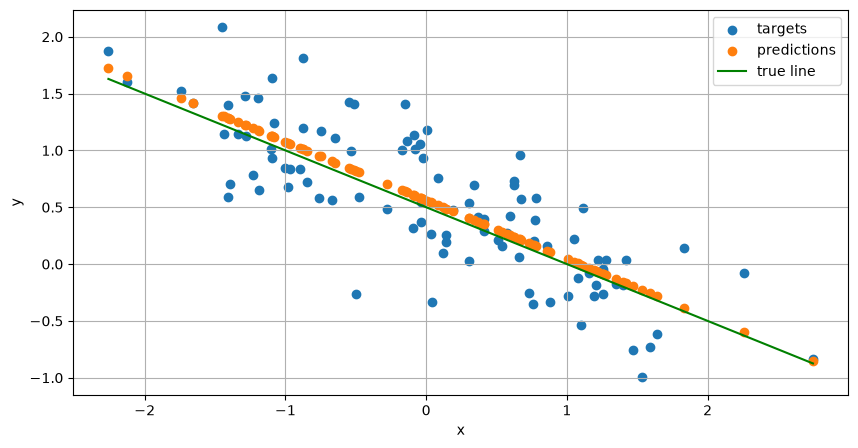

In [23]:
plt.figure(figsize=(10, 5))
plt.scatter(x, y, label='targets')
plt.scatter(x, y_pred, label='predictions')

t = np.linspace(x.min(), x.max(), 100)
plt.plot(t, theta[0] + t * theta[1], label='true line', c='g')
plt.xlabel('x')
plt.ylabel('y')
plt.grid()
plt.legend()

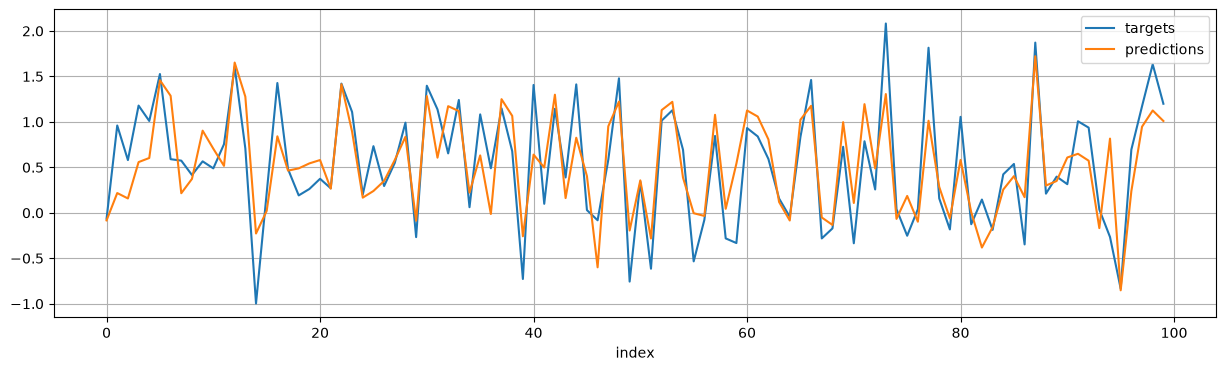

In [24]:
plt.figure(figsize=(15, 4))
plt.plot(y, label='targets')
plt.plot(y_pred, label='predictions')
plt.xlabel('index')
plt.grid()
plt.legend()

## Залишки

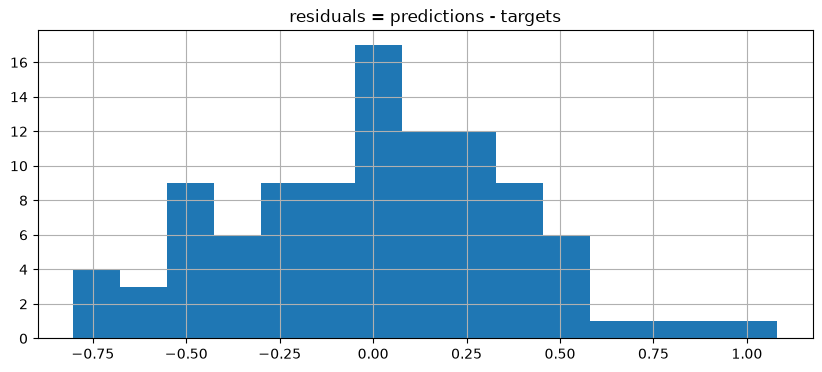

In [25]:
resid = y_pred - y

plt.figure(figsize=(10, 4))
_ = plt.hist(resid, bins=15)
plt.title('residuals = predictions - targets')
plt.grid()

In [26]:
# середнє відхилення
resid.mean()

np.float64(-8.215650382226158e-17)

In [27]:
# середнє абсолютне відхилення та оцінка дисперсії похибок
np.abs(resid).mean(), (resid ** 2).sum() / (n - 2), sigma2

(np.float64(0.3003564205740503), np.float64(0.14515709589511527), 0.2)

Середнє залишків $\approx 0$ (з точністю до машинної похибки). Це не випадковість, а наслідок МНК: з умови $\partial J/\partial\theta_0 = 0$ маємо $\sum_i (y_i - \hat y_i) = 0$.

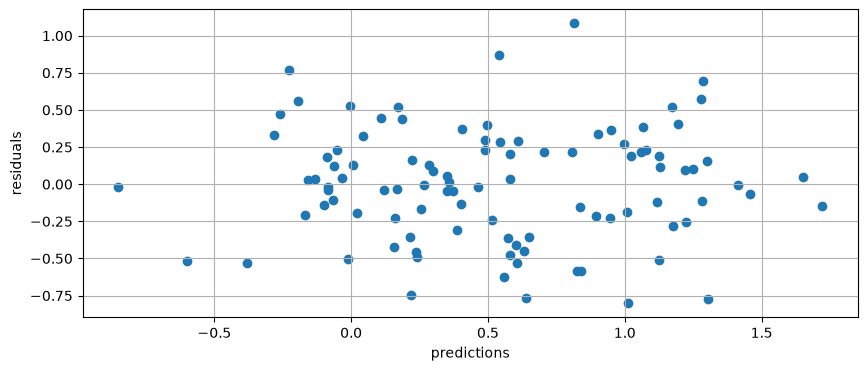

In [28]:
plt.figure(figsize=(10, 4))
plt.scatter(y_pred, resid)
plt.xlabel('predictions')
plt.ylabel('residuals')
plt.grid()

In [29]:
np.corrcoef(resid, y_pred)[0, 1]

np.float64(-9.810109521120675e-17)

Кореляція $\approx 0$, і знову через МНК: $X^T(y - X\hat\theta) = 0$, тобто залишки ортогональні до стовпців $X$, а отже й до $\hat y = X\hat\theta$.

Некорельованість ще не означає незалежність. Але на діаграмі розсіювання структури немає (немає «воронки» чи параболи), а похибки нормальні. Тож залишки та передбачення можна вважати незалежними.

## Чи вдалося гарно оцінити $\theta$?

In [30]:
print("theta     =", theta)
print("theta_est =", theta_est)
print("|theta - theta_est| =", np.abs(theta - theta_est))

theta     = [ 0.5 -0.5]
theta_est = [ 0.560944   -0.51426611]
|theta - theta_est| = [0.060944   0.01426611]


Так. Оцінки близькі до справжніх $(0.5, -0.5)$, похибка порядку $\sigma/\sqrt{n} \approx 0.045$. Для варіанту 1 виконано всі умови: $E\varepsilon = 0$, похибки незалежні від $x$, дисперсія стала.

Якби $E\varepsilon \neq 0$ (наприклад, $\varepsilon \sim Exp$ з варіанту 4), то зсув $E\varepsilon$ «з'їв» би вільний член: $\hat\theta_0 \to \theta_0 + E\varepsilon$, а $\hat\theta_1$ лишилася б добре оціненою.

## Незміщеність і консистентність оцінки МНК

In [31]:
from tqdm import tqdm

N = 1000

mean_est = []
std_est = []

t = range(10, 1001, 10)
for n_ in tqdm(t):
    ests = []
    for _ in range(N):
        x_ = np.random.normal(0, 1, size=n_)
        eps_ = np.random.normal(0, sigma2 ** 0.5, size=n_)
        y_ = theta[0] + x_ * theta[1] + eps_

        X_ = np.stack([np.ones(n_), x_], axis=1)
        ests.append(np.linalg.inv(X_.T.dot(X_)).dot(X_.T).dot(y_))
    ests = np.array(ests)
    mean_est.append(ests.mean(axis=0))
    std_est.append(ests.std(axis=0))

mean_est = np.array(mean_est)
std_est = np.array(std_est)

100%|██████████| 100/100 [00:05<00:00, 19.35it/s]


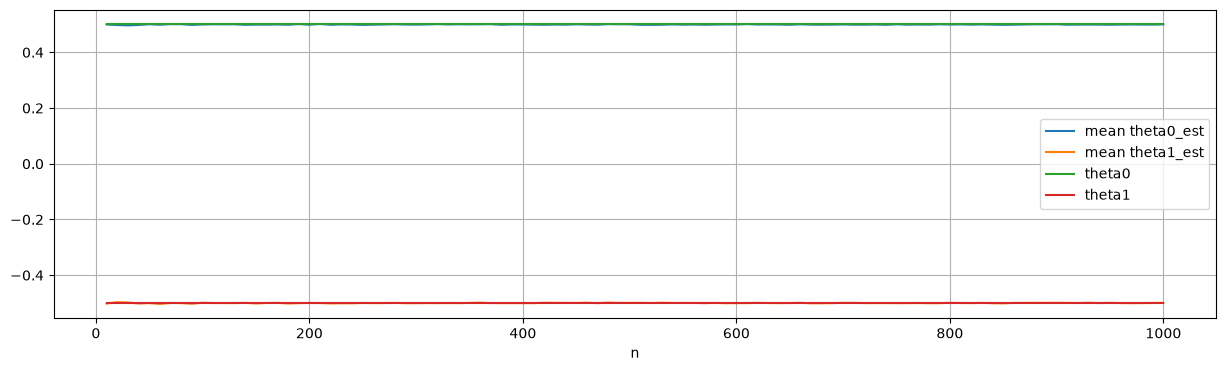

In [32]:
plt.figure(figsize=(15, 4))
plt.plot(t, mean_est[:, 0], label='mean theta0_est')
plt.plot(t, mean_est[:, 1], label='mean theta1_est')
plt.plot(t, [theta[0]] * len(t), label='theta0')
plt.plot(t, [theta[1]] * len(t), label='theta1')
plt.xlabel('n')
plt.grid()
plt.legend()

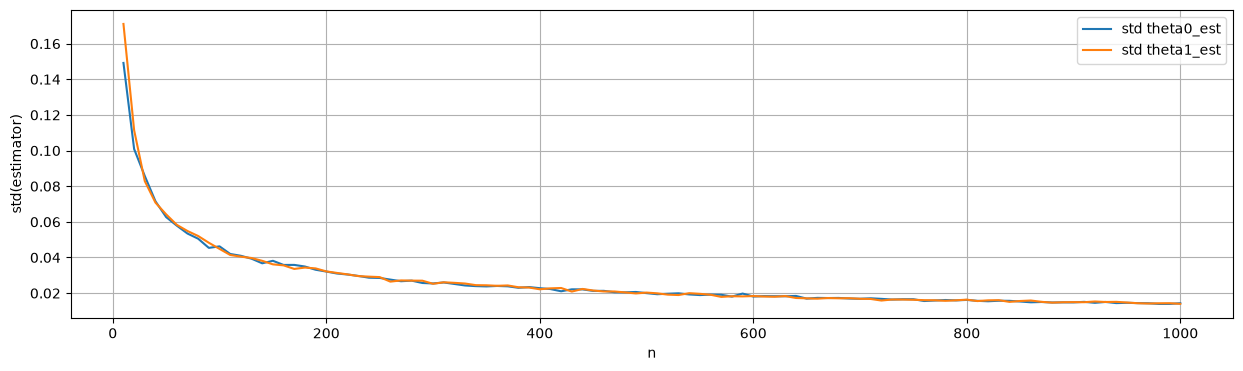

In [33]:
plt.figure(figsize=(15, 4))
plt.plot(t, std_est[:, 0], label='std theta0_est')
plt.plot(t, std_est[:, 1], label='std theta1_est')
plt.xlabel('n')
plt.ylabel('std(estimator)')
plt.grid()
plt.legend()

Середні оцінок збігаються з $\theta$ (незміщеність), а розкид падає до 0 зі зростанням $n$ (консистентність).